# TinySMS: длины текстов, токены и проверка эталонного кода

Анализ исходного `SlavaYus/tinysms_qa_12m` и **отдельно первого миллиона**,
используемого в обучении. Для test без эталонных решений считаются только длины вопросов.

- Символы: `len(text)`, включая пробелы и переводы строк; слова: `text.split()`.
- BPE-токены: наш `artifacts/tokenizer.json`, **без truncation, padding и special tokens**.
  Для сопоставления с decoder отдельно считаем длину кода **плюс EOS**.
- Компиляция: настоящий Python `compile(..., mode="exec")`.
- Выполнение: отдельный изолированный процесс, затем вызов **`solve()` без аргументов**.
- `non_numeric`: возврат строки, tuple, list, None, bool и других нечисловых объектов.
  bool намеренно исключён, хотя Python считает его подклассом int.
- `NaN/Inf` и комплексные числа — отдельные категории, а не обычные конечные числа.
- Ошибки выполнения, отсутствующий `solve`, зависимости, ограничения среды и таймауты
  **не смешиваются** с возвратом нечислового значения.

Числовой результат не доказывает, что решение математически верно. Код из датасета
не исполняется в kernel ноутбука. Для выполнения нужен Linux с Bubblewrap и доступными
user namespaces. Без изоляции notebook останавливает проверку, а не запускает небезопасный fallback.
В Colab/Kaggle эта возможность зависит от ограничений контейнера.

In [1]:
import os
import sys
from pathlib import Path

# Менять здесь. None означает весь исходный train; 10_000 удобно для smoke test.
MAX_TRAIN_ROWS = None
TRAINING_ROWS = 1_000_000
BATCH_SIZE = 8192
CHECK_WORKERS = 2
TOKENIZER_THREADS = 4
EXAMPLE_TIMEOUT = 1.0
LOCAL_CACHE_ONLY = True
RECOMPUTE = False

os.environ["RAYON_NUM_THREADS"] = str(TOKENIZER_THREADS)
if LOCAL_CACHE_ONLY:
    os.environ["HF_DATASETS_OFFLINE"] = "1"
    os.environ["HF_HUB_OFFLINE"] = "1"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/tokenizer.py").exists())
sys.path.insert(0, str(ROOT))
TOKENIZER_PATH = ROOT / "artifacts/tokenizer.json"
OUTPUT_DIR = ROOT / "artifacts/dataset_audit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Project:", ROOT)
print("Artifacts:", OUTPUT_DIR)

Project: /home/carlos/projects/homeworks/nlp/hw2_template
Artifacts: /home/carlos/projects/homeworks/nlp/hw2_template/artifacts/dataset_audit


In [2]:
import hashlib
import json
import time
from collections import Counter, defaultdict, deque
from concurrent.futures import ThreadPoolExecutor
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset, load_from_disk
from IPython.display import display, Markdown, Code
from tokenizers import Tokenizer
from tqdm import tqdm

from src.analysis.code_audit import STATUS, check_codes, check_sandbox
import src.analysis.code_audit as audit_module

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})
pd.set_option("display.max_colwidth", 100)

runtime = {name: version(name) for name in ("datasets", "tokenizers", "numpy", "sympy")}
runtime["python"] = sys.version.split()[0]
runtime.update(check_sandbox())
display(runtime)

/home/carlos/projects/homeworks/nlp/hw2_template/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'datasets': '5.1.0',
 'tokenizers': '0.23.3',
 'numpy': '2.5.4',
 'sympy': '1.14.0',
 'python': '3.13.15',
 'backend': 'bubblewrap',
 'network': 'isolated',
 'memory_per_worker_mib': 512}

## Данные и сопоставление с обучающей выборкой

При `LOCAL_CACHE_ONLY=True` используется уже скачанный HF-кэш. Для первого скачивания
на другой машине установите `False` и выполните notebook с нового kernel.
Проверка ниже сопоставляет исходные тексты и сохранённые токены на нескольких индексах.
Она обнаруживает перестановку или другой токенизатор; это выборочная, не полная сверка.

In [3]:
dataset = load_dataset("SlavaYus/tinysms_qa_12m")
tokenizer = Tokenizer.from_file(str(TOKENIZER_PATH))
eos_id = tokenizer.token_to_id("<eos>")
assert eos_id is not None
raw_train = dataset["train"]
train = (raw_train if MAX_TRAIN_ROWS is None else
         raw_train.select(range(min(MAX_TRAIN_ROWS, len(raw_train)))))
parts = {"train": train, "test": dataset["test"]}
display(pd.DataFrame([
    {"split": name, "rows": len(part), "columns": ", ".join(part.column_names)}
    for name, part in parts.items()
]))

saved_path = ROOT.parent / "hw2/artifacts/tokenized_dataset"
alignment = []
if saved_path.exists():
    saved = load_from_disk(str(saved_path))["train"]
    indices = sorted({0, 1, 100, 10_000, 100_000, min(TRAINING_ROWS, len(saved))-1})
    for index in indices:
        if index >= min(len(saved), len(raw_train)):
            continue
        row, encoded = raw_train[index], saved[index]
        expected_labels = tokenizer.encode(row["code"], add_special_tokens=False).ids
        actual_labels = list(encoded["labels"])
        if actual_labels and actual_labels[-1] == eos_id:
            actual_labels = actual_labels[:-1]
        alignment.append({"index": index,
            "question_matches": tokenizer.encode(row["question"], add_special_tokens=False).ids == encoded["input_ids"],
            "code_matches": expected_labels == actual_labels})
    assert all(row["question_matches"] and row["code_matches"] for row in alignment)
    display(pd.DataFrame(alignment))
else:
    print("Сохранённые токены не найдены; анализируем исходный датасет.")

Using the latest cached version of the dataset since SlavaYus/tinysms_qa_12m couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at /home/carlos/.cache/huggingface/datasets/SlavaYus___tinysms_qa_12m/default/0.0.0/b2724689ff079e9c22efd548fe134bfb29036dbb (last modified on Wed Oct  7 23:41:52 2026).


,split,rows,columns
0,train,11838003,"question, code"
1,test,1919,"question, code"


,index,question_matches,code_matches
0,0,True,True
1,1,True,True
2,100,True,True
3,10000,True,True
4,100000,True,True
5,999999,True,True


## Проверяем классификацию на контролируемых примерах

Эти проверки защищают от ошибки анализа: например, возврат tuple нельзя посчитать числом,
а ошибку деления на ноль — возвратом None. Таймаут ограничивает весь пример, включая импорты.

In [4]:
checks = [
    ("int", "def solve(): return 3", "numeric_finite"),
    ("float", "def solve(): return 2.5", "numeric_finite"),
    ("syntax", "def solve(: return 1", "compile_error"),
    ("string", "def solve(): return '3'", "non_numeric"),
    ("tuple", "def solve(): return (1, 2)", "non_numeric"),
    ("None", "def solve(): return None", "non_numeric"),
    ("bool", "def solve(): return True", "non_numeric"),
    ("division", "def solve(): return 1 / 0", "runtime_error"),
    ("NaN", "def solve(): return float('nan')", "numeric_nonfinite"),
    ("complex", "def solve(): return 1j", "numeric_complex"),
    ("missing", "def another(): return 1", "missing_solve"),
    ("loop", "def solve():\n while True: pass", "timeout"),
    ("sympy", "from sympy import Rational\ndef solve(): return Rational(1,3)", "numeric_finite"),
    ("numpy", "import numpy as np\ndef solve(): return np.float64(3.5)", "numeric_finite"),
    ("sympy_nan", "from sympy import nan\ndef solve(): return nan", "numeric_nonfinite"),
    ("sympy_real", "from sympy import sqrt\ndef solve(): return sqrt(2)", "numeric_finite"),
    ("sympy_complex", "from sympy import I\ndef solve(): return I", "numeric_complex"),
]
probe = check_codes([source for _, source, _ in checks], timeout=EXAMPLE_TIMEOUT)
expected = [STATUS[name] for _, _, name in checks]
assert probe["statuses"] == expected, probe
print(f"Все {len(checks)} контрольных примеров классифицированы правильно.")

Все 17 контрольных примеров классифицированы правильно.


## Полный проход с кэшированием

Массивы длин и статусы записываются по строкам в `.npy` (memory mapping), тексты целиком
в RAM не копируются. Rust-токенизация работает батчами; проверки кода — в изолированных
процессах через ограниченный пул. Готовый кэш повторно используется только при совпадении
fingerprint датасета, токенизатора, Python, настроек и исходного кода checker.

Статистика считается по всем выбранным строкам. Это не случайная подвыборка.
На полном train проход может занять несколько минут. Изменение `MAX_TRAIN_ROWS` меняет
объём анализа и явно отражается в таблицах. Незавершённый раздел пересчитывается.

In [5]:
METRICS = ["question_chars", "question_words", "question_tokens",
           "code_chars", "code_words", "code_tokens", "code_tokens_with_eos"]
tokenizer_hash = hashlib.sha256(TOKENIZER_PATH.read_bytes()).hexdigest()
checker_hash = hashlib.sha256(Path(audit_module.__file__).read_bytes()).hexdigest()

def analyze_split(name, part):
    folder = OUTPUT_DIR / name
    folder.mkdir(exist_ok=True)
    signature = {"dataset": "SlavaYus/tinysms_qa_12m", "fingerprint": part._fingerprint,
                 "rows": len(part), "tokenizer_sha256": tokenizer_hash,
                 "checker_sha256": checker_hash, "runtime": runtime,
                 "timeout": EXAMPLE_TIMEOUT, "batch_size": BATCH_SIZE, "schema": 1}
    manifest_path = folder / "manifest.json"
    fields = METRICS + ["status", "compiled"]
    if not RECOMPUTE and manifest_path.exists():
        manifest = json.loads(manifest_path.read_text())
        if manifest.get("signature") == signature and manifest.get("complete"):
            arrays = {key: np.load(folder / f"{key}.npy", mmap_mode="r") for key in fields}
            assert all(len(values) == len(part) for values in arrays.values())
            print(f"{name}: читаем готовый кэш ({len(part):,} строк)")
            return arrays, manifest

    arrays = {key: np.lib.format.open_memmap(folder / f"{key}.npy", mode="w+",
               dtype="uint8" if key in ("status", "compiled") else "int32",
               shape=(len(part),)) for key in fields}
    arrays["status"][:] = 255
    arrays["compiled"][:] = 0
    examples = defaultdict(list)
    error_types, result_types = Counter(), Counter()
    started = time.perf_counter()

    def accept(start, future):
        report = future.result()
        stop = start + len(report["statuses"])
        arrays["status"][start:stop] = report["statuses"]
        arrays["compiled"][start:stop] = report["compiled"]
        error_types.update(report["error_types"])
        result_types.update(report["result_types"])
        for item in report["examples"]:
            status = item["status"]
            if len(examples[status]) < 20:
                examples[status].append(dict(item, index=start + item["offset"]))

    pending = deque()
    with ThreadPoolExecutor(max_workers=CHECK_WORKERS) as executor:
        progress = tqdm(total=len(part), desc=name, mininterval=10.0)
        for start in range(0, len(part), BATCH_SIZE):
            batch = part[start:start+BATCH_SIZE]
            questions, codes = batch["question"], batch["code"]
            stop = start + len(questions)
            for prefix, texts in (("question", questions), ("code", codes)):
                valid = np.fromiter((isinstance(text, str) and bool(text.strip()) for text in texts),
                                    dtype=bool, count=len(texts))
                arrays[f"{prefix}_chars"][start:stop] = [len(text) if ok else -1 for text, ok in zip(texts, valid)]
                arrays[f"{prefix}_words"][start:stop] = [len(text.split()) if ok else -1 for text, ok in zip(texts, valid)]
                encoded = tokenizer.encode_batch([text if ok else "" for text, ok in zip(texts, valid)],
                                                 add_special_tokens=False)
                lengths = np.fromiter((len(item.ids) for item in encoded), dtype=np.int32, count=len(texts))
                del encoded
                lengths[~valid] = -1
                arrays[f"{prefix}_tokens"][start:stop] = lengths
                if prefix == "code":
                    arrays["code_tokens_with_eos"][start:stop] = np.where(valid, lengths + 1, -1)
            if all(code is None or not str(code).strip() for code in codes):
                arrays["status"][start:stop] = STATUS["missing_code"]
            else:
                pending.append((start, executor.submit(check_codes, codes, timeout=EXAMPLE_TIMEOUT)))
            if len(pending) >= CHECK_WORKERS * 2:
                accept(*pending.popleft())
            progress.update(stop-start)
        while pending:
            accept(*pending.popleft())
        progress.close()
    assert not np.any(arrays["status"] == 255), "Some rows were not checked"
    assert np.array_equal(arrays["status"] == STATUS["compile_error"], arrays["compiled"] == 2)
    for values in arrays.values():
        values.flush()
    manifest = {"signature": signature, "complete": True,
                "elapsed_seconds": time.perf_counter()-started,
                "examples": dict(examples), "error_types": dict(error_types),
                "result_types": dict(result_types)}
    temporary = folder / "manifest.tmp"
    temporary.write_text(json.dumps(manifest, ensure_ascii=False, indent=2))
    temporary.replace(manifest_path)
    return arrays, manifest

In [6]:
results = {name: analyze_split(name, part) for name, part in parts.items()}
train_arrays, train_manifest = results["train"]
used_rows = min(TRAINING_ROWS, len(train))
views = {
    f"train: все {len(train):,}": train_arrays,
    f"train: первые {used_rows:,}": {key: values[:used_rows] for key, values in train_arrays.items()},
    f"test: {len(parts['test']):,}": results["test"][0],
}
print("Проход закончен. Результаты сохранены:", OUTPUT_DIR)

train: читаем готовый кэш (11,838,003 строк)
test: читаем готовый кэш (1,919 строк)
Проход закончен. Результаты сохранены: /home/carlos/projects/homeworks/nlp/hw2_template/artifacts/dataset_audit


## Повторная проверка ошибок импорта с SciPy

Некоторые решения используют SciPy. После полного прохода повторно проверяем только строки
с `dependency_error`: длины и токены пересчитывать не нужно. Оставшиеся ошибки импорта
не объявляются нечисловыми результатами. Версия SciPy и число повторных проверок сохраняются
в manifest; изменение версии после готового аудита требует `RECOMPUTE=True`.

In [7]:
dependency_versions = {"scipy": version("scipy")}
display(dependency_versions)
for split_name, part in parts.items():
    arrays, manifest = results[split_name]
    previous = manifest.get("dependency_recheck_versions")
    if previous == dependency_versions:
        print(f"{split_name}: повторная проверка уже сохранена в кэше")
        continue
    if previous is not None:
        raise RuntimeError("Версия SciPy изменилась: установите RECOMPUTE=True")
    indices = np.flatnonzero(arrays["status"] == STATUS["dependency_error"])
    error_types = Counter({k: v for k, v in manifest["error_types"].items()
                           if not k.startswith(str(STATUS["dependency_error"]) + ":")})
    result_types = Counter({k: v for k, v in manifest["result_types"].items()
                            if not k.startswith(str(STATUS["dependency_error"]) + ":")})
    examples = {str(k): list(v) for k, v in manifest["examples"].items()
                if str(k) != str(STATUS["dependency_error"])}
    patches = []
    started = time.perf_counter()
    for start in range(0, len(indices), 1024):
        chunk_indices = indices[start:start+1024]
        codes = part[chunk_indices.tolist()]["code"]
        report = check_codes(codes, timeout=EXAMPLE_TIMEOUT)
        patches.append((chunk_indices, report))
        error_types.update(report["error_types"])
        result_types.update(report["result_types"])
        for item in report["examples"]:
            key = str(item["status"])
            examples.setdefault(key, [])
            if len(examples[key]) < 20:
                examples[key].append(dict(item, index=int(chunk_indices[item["offset"]])))
    # Сначала получаем все результаты, затем изменяем массивы и manifest.
    writable = {key: np.load(OUTPUT_DIR / split_name / f"{key}.npy", mmap_mode="r+")
                for key in ("status", "compiled")}
    for chunk_indices, report in patches:
        writable["status"][chunk_indices] = report["statuses"]
        writable["compiled"][chunk_indices] = report["compiled"]
    for values in writable.values():
        values.flush()
    manifest.update({"examples": examples, "error_types": dict(error_types),
                     "result_types": dict(result_types),
                     "dependency_recheck_versions": dependency_versions,
                     "dependency_rechecked_rows": len(indices),
                     "dependency_recheck_seconds": time.perf_counter()-started})
    temporary = OUTPUT_DIR / split_name / "manifest.tmp"
    temporary.write_text(json.dumps(manifest, ensure_ascii=False, indent=2))
    temporary.replace(OUTPUT_DIR / split_name / "manifest.json")
    print(f"{split_name}: повторно проверено {len(indices):,}; "
          f"ошибок импорта осталось {np.count_nonzero(writable['status'] == STATUS['dependency_error']):,}")

{'scipy': '1.18.1'}

train: повторная проверка уже сохранена в кэше
test: повторная проверка уже сохранена в кэше


## Распределения длин

`p95`, например, означает: 95% текстов не длиннее этого значения.
Пропущенные эталонные коды не считаются текстами нулевой длины: они исключены из статистики кода.

In [8]:
length_rows = []
for scope, arrays in views.items():
    for metric in METRICS:
        values = arrays[metric]
        valid = values[values >= 0]
        if not len(valid):
            continue
        q = np.percentile(valid, [50, 90, 95, 99, 99.9])
        length_rows.append({"scope": scope, "metric": metric, "count": len(valid),
            "missing": len(values)-len(valid), "min": int(valid.min()), "mean": float(valid.mean()),
            **dict(zip(["p50", "p90", "p95", "p99", "p99.9"], q)), "max": int(valid.max())})
length_summary = pd.DataFrame(length_rows)
display(length_summary.round(2))
length_summary.to_csv(OUTPUT_DIR / "length_summary.csv", index=False)

,scope,metric,count,missing,min,mean,p50,p90,p95,p99,p99.9,max
0,"train: все 11,838,003",question_chars,11838003,0,11,191.91,176.0,297.0,341.0,441.0,564.00,2892
1,"train: все 11,838,003",question_words,11838003,0,2,37.16,34.0,56.0,64.0,83.0,107.00,588
2,"train: все 11,838,003",question_tokens,11838003,0,4,45.21,41.0,70.0,79.0,103.0,133.00,744
3,"train: все 11,838,003",code_chars,11838003,0,20,258.90,225.0,417.0,514.0,783.0,1139.00,7712
4,"train: все 11,838,003",code_words,11838003,0,4,32.94,28.0,50.0,65.0,111.0,168.00,561
5,"train: все 11,838,003",code_tokens,11838003,0,7,71.94,62.0,118.0,144.0,212.0,306.00,1223
6,"train: все 11,838,003",code_tokens_with_eos,11838003,0,8,72.94,63.0,119.0,145.0,213.0,307.00,1224
7,"train: первые 1,000,000",question_chars,1000000,0,11,177.73,161.0,277.0,323.0,436.0,605.00,2892
8,"train: первые 1,000,000",question_words,1000000,0,2,35.10,32.0,54.0,62.0,84.0,115.00,588
9,"train: первые 1,000,000",question_tokens,1000000,0,4,42.84,39.0,66.0,77.0,105.0,146.00,744


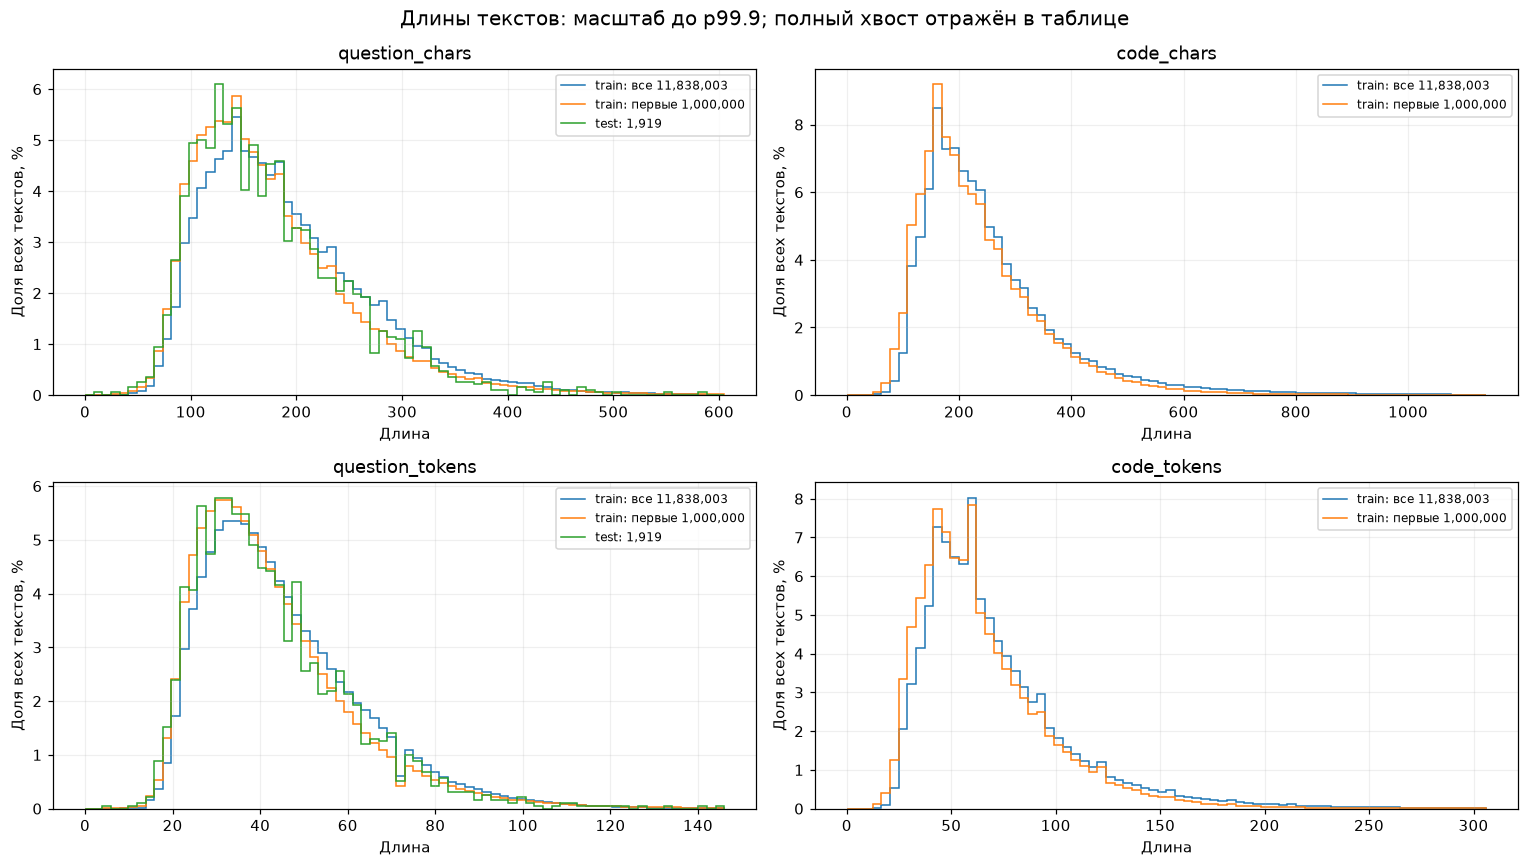

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for axis, metric in zip(axes.flat, ["question_chars", "code_chars", "question_tokens", "code_tokens"]):
    relevant = length_summary[length_summary.metric == metric]
    upper = max(10, int(relevant["p99.9"].max()))
    edges = np.linspace(0, upper, 75)
    for scope, arrays in views.items():
        values = arrays[metric]
        valid = values[values >= 0]
        if not len(valid):
            continue
        counts, _ = np.histogram(valid, bins=edges)
        axis.stairs(counts / len(valid) * 100, edges, label=scope)
    axis.set(title=metric, xlabel="Длина", ylabel="Доля всех текстов, %")
    axis.legend(fontsize=8)
fig.suptitle("Длины текстов: масштаб до p99.9; полный хвост отражён в таблице", fontsize=13)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "length_histograms.png", dpi=180)
plt.show()

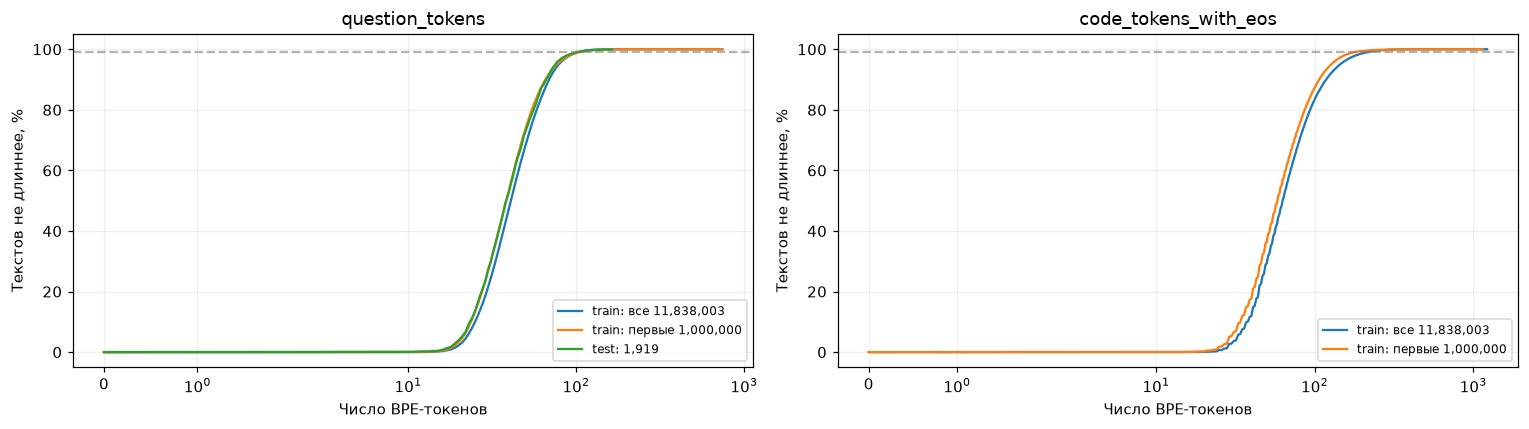

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for axis, metric in zip(axes, ["question_tokens", "code_tokens_with_eos"]):
    for scope, arrays in views.items():
        valid = arrays[metric][arrays[metric] >= 0]
        if not len(valid):
            continue
        counts = np.bincount(valid)
        axis.plot(np.arange(len(counts)), np.cumsum(counts) / len(valid) * 100, label=scope)
    axis.set(title=metric, xlabel="Число BPE-токенов", ylabel="Текстов не длиннее, %", xscale="symlog")
    axis.axhline(99, color="gray", linestyle="--", alpha=.6)
    axis.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "token_length_cdf.png", dpi=180)
plt.show()

In [11]:
limit_rows = []
for scope, arrays in views.items():
    for column, limits in (("question_tokens", [128, 256, 512, 1024]),
                            ("code_tokens_with_eos", [128, 256, 512, 1024, 1280])):
        valid = arrays[column][arrays[column] >= 0]
        if not len(valid):
            continue
        for limit in limits:
            count = int(np.count_nonzero(valid > limit))
            limit_rows.append({"scope": scope, "metric": column, "limit": limit,
                               "exceed": count, "exceed_pct": 100 * count / len(valid)})
limit_summary = pd.DataFrame(limit_rows)
display(limit_summary.round(5))
limit_summary.to_csv(OUTPUT_DIR / "length_limits.csv", index=False)

,scope,metric,limit,exceed,exceed_pct
0,"train: все 11,838,003",question_tokens,128,16600,0.14023
1,"train: все 11,838,003",question_tokens,256,63,0.00053
2,"train: все 11,838,003",question_tokens,512,3,0.00003
3,"train: все 11,838,003",question_tokens,1024,0,0.00000
4,"train: все 11,838,003",code_tokens_with_eos,128,912414,7.70750
5,"train: все 11,838,003",code_tokens_with_eos,256,44373,0.37484
6,"train: все 11,838,003",code_tokens_with_eos,512,171,0.00144
7,"train: все 11,838,003",code_tokens_with_eos,1024,4,0.00003
8,"train: все 11,838,003",code_tokens_with_eos,1280,0,0.00000
9,"train: первые 1,000,000",question_tokens,128,2658,0.26580


## Сколько решений не компилируется и возвращает не число

Категории взаимоисключающие и покрывают все строки. `numeric_finite` — конечное
действительное число, включая Fraction/Decimal и числовые скаляры NumPy/SymPy.
`dependency_error` и `environment_error` отражают условия проверки, поэтому автоматически
объявлять такие примеры некорректными нельзя. Таймаут тоже означает «не удалось проверить
за выбранное время», а не доказанную ошибку решения. Все проверки выполнены в версии Python,
указанной в начале notebook; аннотация `-> int` не используется как проверка типа.

In [12]:
quality_rows = []
for scope, arrays in list(views.items())[:2]:
    counts = np.bincount(arrays["status"], minlength=max(STATUS.values())+1)
    for name, status in STATUS.items():
        quality_rows.append({"scope": scope, "status": name, "count": int(counts[status]),
                             "percent": 100 * int(counts[status]) / len(arrays["status"])})
quality_summary = pd.DataFrame(quality_rows)
display(quality_summary.pivot(index="status", columns="scope", values="count"))
quality_summary.to_csv(OUTPUT_DIR / "code_quality_summary.csv", index=False)

headline = []
for scope, arrays in list(views.items())[:2]:
    status, compiled = arrays["status"], arrays["compiled"]
    headline.append({"scope": scope, "examples": len(status),
        "compile_failed": int(np.count_nonzero(compiled == 2)),
        "compile_unchecked": int(np.count_nonzero(compiled == 0)),
        "returned_non_numeric": int(np.count_nonzero(status == STATUS["non_numeric"])),
        "runtime_error": int(np.count_nonzero(status == STATUS["runtime_error"])),
        "finite_real_number": int(np.count_nonzero(status == STATUS["numeric_finite"]))})
headline = pd.DataFrame(headline)
display(headline)
headline.to_csv(OUTPUT_DIR / "audit_headline.csv", index=False)

scope,"train: все 11,838,003","train: первые 1,000,000"
status,,
compile_error,1,0
dependency_error,11,5
environment_error,0,0
missing_code,0,0
missing_solve,0,0
non_numeric,280326,35088
numeric_complex,223,37
numeric_finite,11372602,964856
numeric_nonfinite,29,2


,scope,examples,compile_failed,compile_unchecked,returned_non_numeric,runtime_error,finite_real_number
0,"train: все 11,838,003",11838003,1,0,280326,184808,11372602
1,"train: первые 1,000,000",1000000,0,0,35088,11,964856


In [13]:
types = pd.Series(train_manifest["result_types"], name="count").rename_axis("status:type").reset_index()
if len(types):
    types[["status_id", "return_type"]] = types["status:type"].str.split(":", n=1, expand=True)
    display(types[types.status_id == str(STATUS["non_numeric"])][["return_type", "count"]]
            .sort_values("count", ascending=False))
errors = pd.Series(train_manifest["error_types"], name="count").rename_axis("status:exception")
display(errors.sort_values(ascending=False).head(20))

,return_type,count
2,tuple,210008
3,str,49661
4,list,6607
7,bool,6069
5,NoneType,4026
6,ellipsis,3049
8,dict,320
24,Add,306
26,Mul,87
17,builtin_function_or_method,45


status:exception
2:NameError            184683
2:UnboundLocalError        88
2:RuntimeError             28
8:ImportError              11
2:TypeError                 5
2:ValueError                3
1:IndentationError          1
2:KeyError                  1
Name: count, dtype: int64

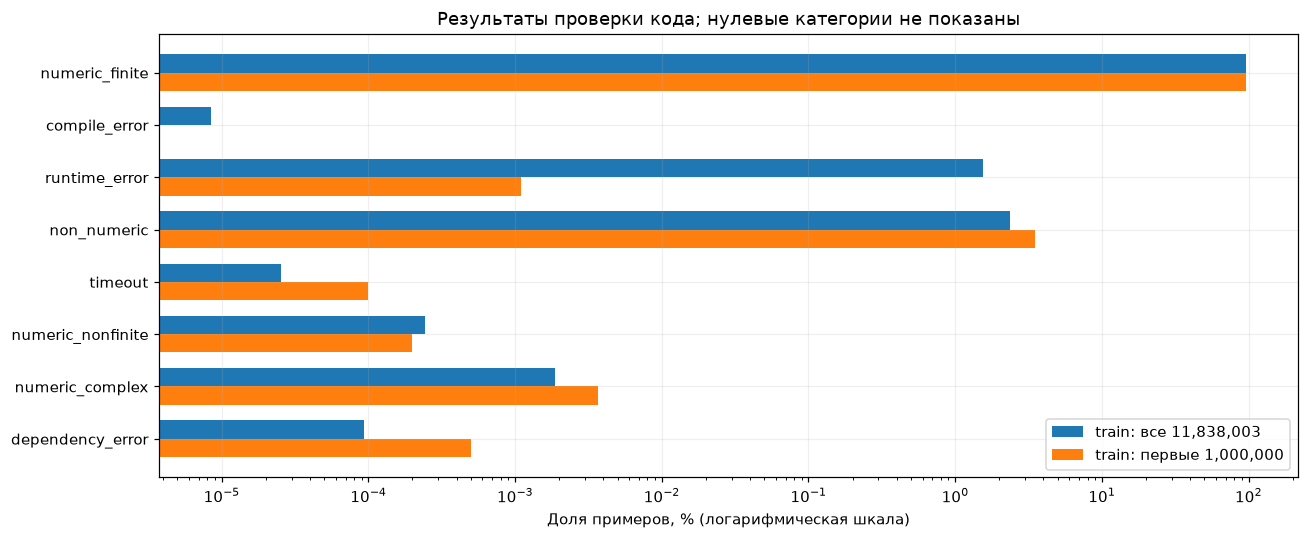

In [14]:
fig, axis = plt.subplots(figsize=(12, 5))
labels = quality_summary.groupby("status", sort=False)["count"].sum()
labels = labels[labels > 0].index.tolist()
positions = np.arange(len(labels))
for i, (scope, frame) in enumerate(quality_summary.groupby("scope", sort=False)):
    values = frame.set_index("status").loc[labels, "percent"].to_numpy()
    present = values > 0
    axis.barh(positions[present] + (i - 0.5) * 0.35, values[present],
              height=0.35, label=scope)
axis.set_yticks(positions, labels)
axis.invert_yaxis()
axis.set(xscale="log", xlabel="Доля примеров, % (логарифмическая шкала)",
         title="Результаты проверки кода; нулевые категории не показаны")
axis.legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "code_quality.png", dpi=180)
plt.show()

## Примеры проблем и строки для последующего анализа

Полный массив статусов хранится в `train/status.npy`: индекс совпадает с исходным train.
Ниже выводится ограниченное число примеров каждой категории. Датасет автоматически
не фильтруется и не перезаписывается. Возврат нескольких чисел или "Yes" может соответствовать
условию задачи — такие строки не обязательно плохие, но выходят за контракт «одно число».

In [15]:
example_rows = []
for status_id, examples in train_manifest["examples"].items():
    name = next(name for name, value in STATUS.items() if value == int(status_id))
    for item in examples:
        row = train[item["index"]]
        example_rows.append({"index": item["index"], "status": name,
            "result_type": item["result_type"], "error": item["error"],
            "question": row["question"], "code": row["code"]})
examples_df = pd.DataFrame(example_rows)
if len(examples_df):
    display(examples_df[["index", "status", "result_type", "error", "question"]].head(30))
    examples_df.to_json(OUTPUT_DIR / "problem_examples.json", orient="records", force_ascii=False, indent=2)
    for name in ("compile_error", "non_numeric", "runtime_error", "dependency_error"):
        matches = examples_df[examples_df.status == name]
        if len(matches):
            example = matches.iloc[0]
            display(Markdown(f"**{name}, train[{example['index']}]** — {example['question']}"))
            display(Code(example["code"], language="python"))

,index,status,result_type,error,question
0,51,non_numeric,tuple,NaN,Student: The perimeter of a rectangle is 50 cm and its length is twice its width. What are the d...
1,57,non_numeric,str,NaN,"A triangle has sides of length 5cm, 6cm and 7cm. Is the triangle a right-angled triangle?"
2,97,non_numeric,tuple,NaN,"In a flock of birds, there are 5 times as many birds than there are ducks. If there are 30 ducks..."
3,8204,non_numeric,tuple,NaN,Jake's bedroom has an area of 256 square feet. He wants to put furniture in it that takes up hal...
4,8223,non_numeric,tuple,NaN,"Mia wants to bake some cupcakes for her friends. She can bake 12 cupcakes at a time in her oven,..."
5,8281,non_numeric,str,NaN,Anna and Jane run a race together that is a total of 4 kilometers. Anna runs at a speed of 12 ki...
6,16422,non_numeric,tuple,NaN,Possible new questions are: Alice buys 2 pizzas and 3 drinks for her friends. One pizza costs $1...
7,16477,non_numeric,str,NaN,"Alex has 120 pens, and he wants to distribute them equally among 15 of his co-workers. How many ..."
8,16518,non_numeric,tuple,NaN,"Mary is three times as old as her daughter. In four years, Mary will be twice as old as her daug..."
9,24588,non_numeric,tuple,NaN,"A recipe calls for 3/4 cup of milk and 1/3 cup of flour. If you want to double the recipe, how m..."


**compile_error, train[1553747]** — A fruit vendor sells bananas for $0.25 each. If he sells 120 bananas in a week, how much money does he earn?

def solve() -> int:

**non_numeric, train[51]** — Student: The perimeter of a rectangle is 50 cm and its length is twice its width. What are the dimensions of the rectangle?

def solve() -> int:
    perimeter = 50
    ratio = 2
    width = perimeter / 2 / (ratio + 1)
    length = width * ratio
    result = (length, width)

    return result

**runtime_error, train[121510]** — Eleven apples and three bananas cost $6.01. Eight apples and four bananas cost $4.52. What is the price of one apple and one banana?

def solve() -> int:
    from sympy import symbols, Eq, solve
    
    a, b = symbols('a b')
    eq1 = Eq(11*a + 3*b - 6.01)
    eq2 = Eq(8*a + 4*b - 4.52)
    sol = solve((eq1, eq2), (a, b))
    result = (sol[a], sol[b])

    return result

**dependency_error, train[250471]** — Student: A jewelry store has 18 gold rings and 24 silver rings. What is the ratio of the number of gold rings to the number of silver rings?

def solve() -> int:
    gold = 18
    silver = 24
    ratio = gold / silver
    from fractions import gcd
    common_divisor = gcd(gold, silver)
    simplified_ratio = ratio / common_divisor
    result = simplified_ratio

    return result

In [16]:
display(Markdown("### Итог"))
for row in headline.to_dict("records"):
    display(Markdown(
        f"**{row['scope']}**: из {row['examples']:,} примеров "
        f"**{row['compile_failed']:,}** не компилируются; "
        f"**{row['returned_non_numeric']:,}** возвращают нечисловой объект; "
        f"**{row['runtime_error']:,}** завершаются ошибкой выполнения. "
        f"Конечное действительное число возвращают **{row['finite_real_number']:,}**."
    ))
display(Markdown("CSV, массивы по строкам, примеры ошибок и PNG-графики сохранены в `artifacts/dataset_audit/`."))

### Итог

**train: все 11,838,003**: из 11,838,003 примеров **1** не компилируются; **280,326** возвращают нечисловой объект; **184,808** завершаются ошибкой выполнения. Конечное действительное число возвращают **11,372,602**.

**train: первые 1,000,000**: из 1,000,000 примеров **0** не компилируются; **35,088** возвращают нечисловой объект; **11** завершаются ошибкой выполнения. Конечное действительное число возвращают **964,856**.

CSV, массивы по строкам, примеры ошибок и PNG-графики сохранены в `artifacts/dataset_audit/`.